# Exploratory Data Analysis

Initial inspection of the final hit-song classification dataset.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Load the Dataset

In [18]:
df = pd.read_csv("../data/final_dataset.csv")
df.head()

,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,hit
0,Perfidia Cha Cha,['Cal Tjader'],0.858,0.449,-16.531,0.0658,0.77400,0.062500,0.1130,0.890,127.066,0
1,Gir Kanıma,['Harun Kolçak'],0.759,0.714,-9.449,0.0564,0.00163,0.000012,0.0173,0.492,119.775,0
2,It's Over Now,['112'],0.660,0.710,-4.541,0.0409,0.01060,0.000007,0.0736,0.233,97.988,1
3,The Pusher,['Blind Melon'],0.438,0.576,-8.727,0.0320,0.03020,0.000011,0.0988,0.742,165.277,0
4,Toys In The Attic,['Aerosmith'],0.219,0.928,-9.997,0.0697,0.00100,0.000002,0.3410,0.446,197.462,0


## Dataset Structure and Data Quality

In [19]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values by column:")
print(df.isna().sum())
print("\nDuplicate row count:", df.duplicated().sum())

Dataset shape: (10000, 12)

Column names:
['name', 'artists', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'hit']

Data types:
name                 object
artists              object
danceability        float64
energy              float64
loudness            float64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
hit                   int64
dtype: object

Missing values by column:
name                0
artists             0
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
hit                 0
dtype: int64

Duplicate row count: 0


## Hit versus Non-Hit Class Distribution

In [20]:
final_df = df
hit_counts = final_df["hit"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "count": [
        hit_counts.get(1, 0),
        hit_counts.get(0, 0)
    ],
    "percentage": [
        hit_counts.get(1, 0) / len(final_df) * 100,
        hit_counts.get(0, 0) / len(final_df) * 100
    ]
}, index=["HIT (1)", "NON-HIT (0)"])

display(class_distribution)


,count,percentage
HIT (1),4000,40.0
NON-HIT (0),6000,60.0


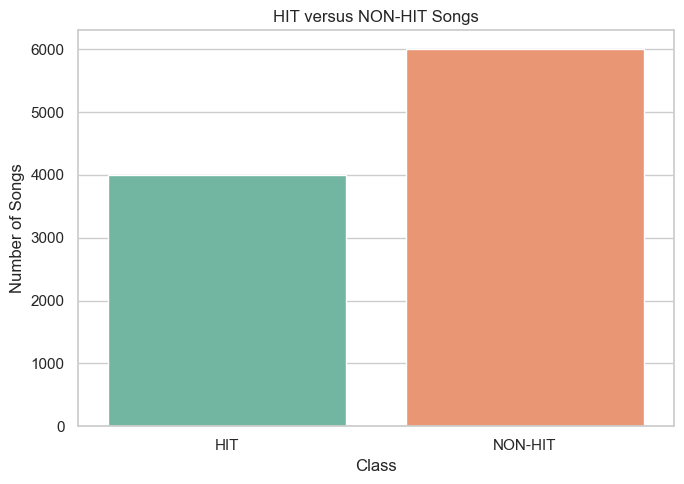

In [21]:
plot_data = df["hit"].map({1: "HIT", 0: "NON-HIT"})

plt.figure(figsize=(7, 5))
sns.countplot(x=plot_data, order=["HIT", "NON-HIT"], palette="Set2")
plt.title("HIT versus NON-HIT Songs")
plt.xlabel("Class")
plt.ylabel("Number of Songs")
plt.tight_layout()
plt.show()

## Spotify Audio Feature Descriptive Statistics

In [22]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]

df[audio_features].describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,0.575383,0.567479,-9.809658,0.095666,0.386416,0.081891,0.202931,0.567489,118.839146
std,0.161696,0.238589,4.740631,0.163843,0.333983,0.227581,0.173031,0.251250,29.314166
min,0.000000,0.000020,-48.488000,0.000000,0.000000,0.000000,0.009670,0.000000,0.000000
25%,0.470000,0.393000,-12.371000,0.033200,0.065950,0.000000,0.094800,0.363000,96.360500
50%,0.590000,0.584000,-9.013000,0.042900,0.302000,0.000014,0.134000,0.582000,117.600500
75%,0.693000,0.760000,-6.310750,0.071125,0.693000,0.002812,0.262000,0.779250,136.195250
max,0.988000,0.998000,0.333000,0.970000,0.996000,0.997000,0.997000,0.995000,216.072000
